In [1]:
import pandas as pd
import numpy as no
import matplotlib.pyplot as plt
import seaborn as sns

## Data Set Information
- This data set showcases 5,000 movies spanning from 1980 to 2024. It contains information of these movies such as its assigned ID name, the year and decade it came out, how long it is, the genre, runtime, ratings, and money used and made from it. There is an addition part of the data used to indicate whether it was a blockbuster.
- My research question asks "What contributes to a movie being a blockbuster?", we can use this data to interpret the factors that goes into assigning this title
- There aren't any duplicates or missing values
- In the previous part I converted blockbuster to be a string, however for these analyses I kept it numeric for the later correlation graphs
<br>
Data Set Title= movie_blockbusters

<br> Source: Kaggle- <br> <https://www.kaggle.com/datasets/vedauv/what-makes-a-movie-a-blockbuster-5000-films>

In [2]:
df= pd.read_csv('movie_blockbusters.csv')
df

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
0,1,Movie_0001,2020,2020s,Comedy,96,2.089233e+07,2.739209e+07,6.499763e+06,0.311,7.0,216326,9.64,0
1,2,Movie_0002,1981,1980s,Sci-Fi,128,3.063336e+08,1.237479e+09,9.311449e+08,3.040,5.3,49703,7.65,1
2,3,Movie_0003,1995,1990s,Horror,79,8.793950e+06,4.667246e+06,-4.126704e+06,-0.469,3.4,9476,16.68,0
3,4,Movie_0004,1988,1980s,Comedy,101,3.871710e+06,1.612737e+06,-2.258972e+06,-0.583,8.2,15698,2.93,0
4,5,Movie_0005,2023,2020s,Documentary,75,1.283539e+06,5.743469e+05,-7.091917e+05,-0.553,4.3,38698,9.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,Movie_4996,2021,2020s,Comedy,71,2.548402e+07,5.560086e+07,3.011683e+07,1.182,7.4,181516,1.17,0
4996,4997,Movie_4997,2002,2000s,Comedy,75,9.045585e+07,4.017441e+07,-5.028144e+07,-0.556,4.4,14308,8.32,0
4997,4998,Movie_4998,1998,1990s,Documentary,79,7.906923e+05,2.595448e+05,-5.311475e+05,-0.672,6.4,13156,15.77,0
4998,4999,Movie_4999,2012,2010s,Documentary,98,8.636783e+06,1.480145e+07,6.164669e+06,0.714,5.7,340215,3.55,0


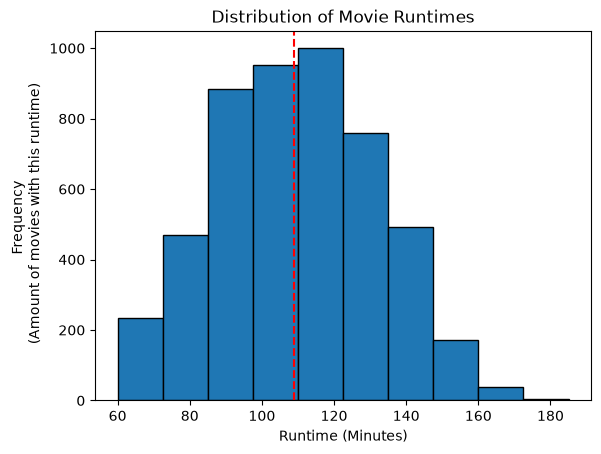

In [105]:
plt.hist(df['runtime_min'], edgecolor='black')
plt.title('Distribution of Movie Runtimes')
plt.xlabel('Runtime (Minutes)')
plt.axvline(df['runtime_min'].median(), color='red', linestyle='--')
plt.ylabel('Frequency \n (Amount of movies with this runtime)')
plt.show()

This graph represents the runtime minutes of all the movies in the dataset. It is approximately normal. It ranges from 60 to 185 and it showcases that the average movie runtime is around 109 minutes. The dashed line represents the median which is 109.

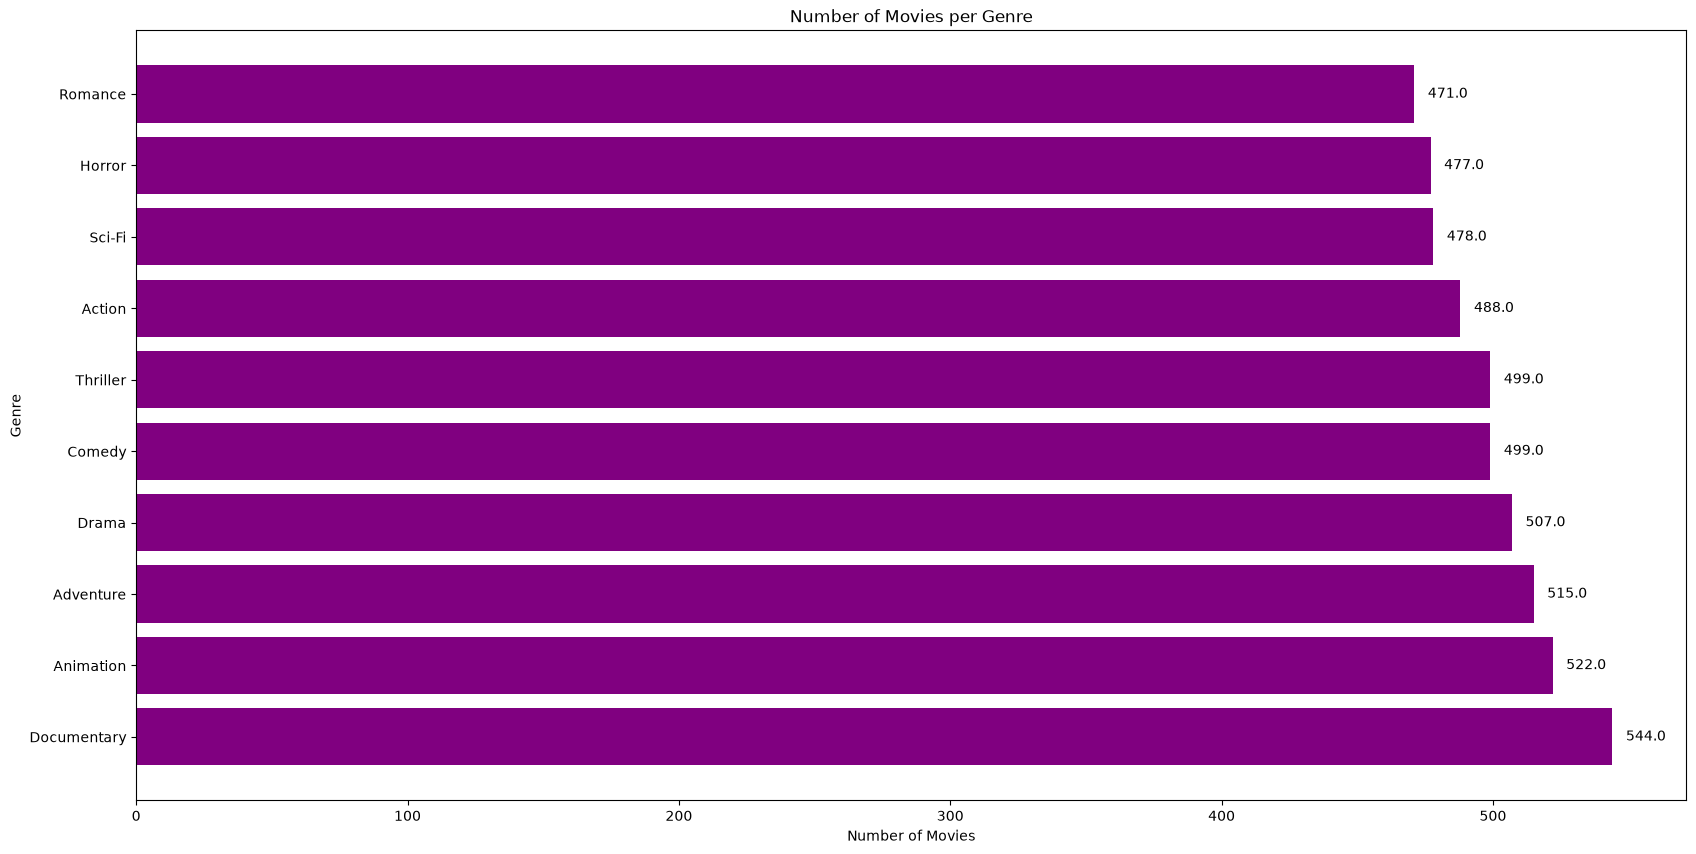

In [99]:
plt.figure(figsize=(20,10))
genre_count=df['genre'].value_counts()
plt.barh(genre_count.index, genre_count.values, color='purple')
plt.title('Number of Movies per Genre')
plt.ylabel('Genre')
plt.xlabel('Number of Movies')
for i, v in enumerate(genre_count):
    plt.text(v+5, i,f'{v:.1f}', ha='left', va='center')

plt.show()

This graph represents the amount of movies per genre. It ranges from 471 (Romance having the least movies) to 544 (Documentary having the most movies). This spread only being 73 means that overall a similar amount of movies are being released in each genre inside this dataset.

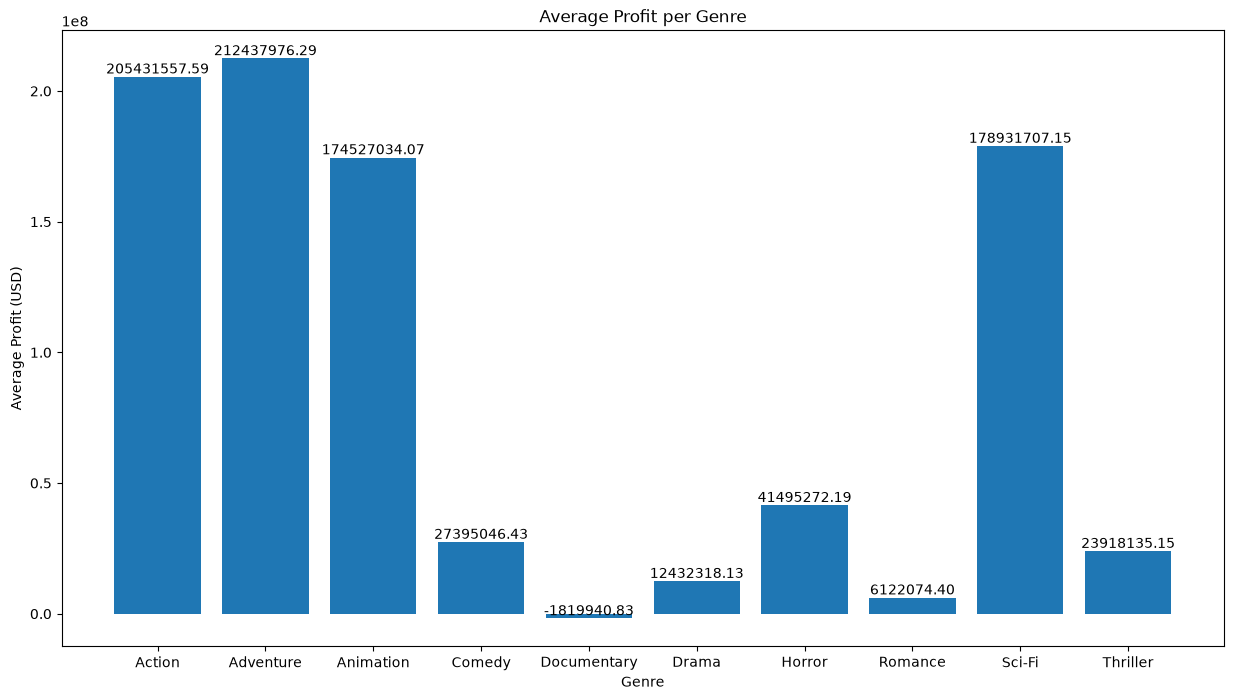

In [100]:
genre_profit= df.groupby('genre')['profit_usd'].mean()
plt.figure(figsize=(15,8))
plt.bar(genre_profit.index, genre_profit.values)
plt.xlabel('Genre')
plt.title('Average Profit per Genre')
plt.ylabel('Average Profit (USD)')
for i, v in enumerate(genre_profit):
    plt.text(i, v+500,f'{v:.2f}', ha='center', va='bottom')
plt.show()

This graph represents the average profit of each movie genre. The genre with the highest profit is Adventure with around 212.4 million usd in profit. The genre with the lowest is Documentary with around -1.8 million in profit.

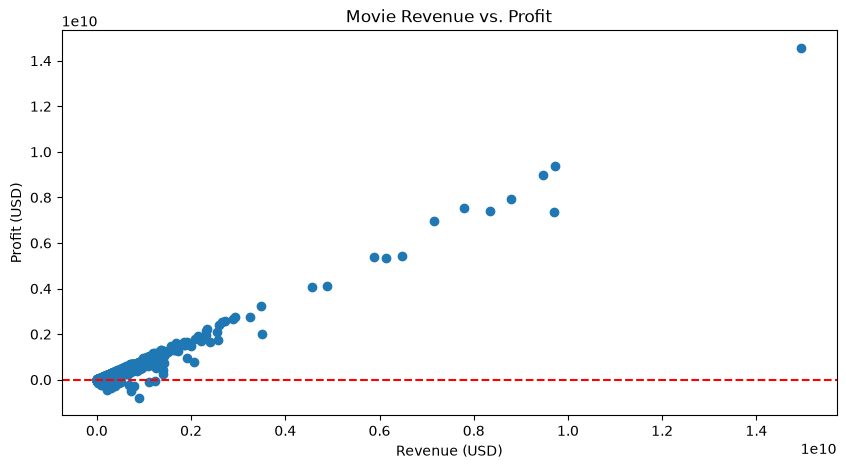

In [108]:
plt.figure(figsize=(10,5))
plt.title('Movie Revenue vs. Profit')
plt.xlabel('Revenue (USD)')
plt.ylabel('Profit (USD)')
plt.scatter(df['revenue_usd'], df['profit_usd'])
plt.axhline(0, color='red', linestyle='--')
plt.show()

This graph represents the relationship between a movie's revenue and profit in USD. We see a strong positive correlation, implying that more revenue equals more profit.

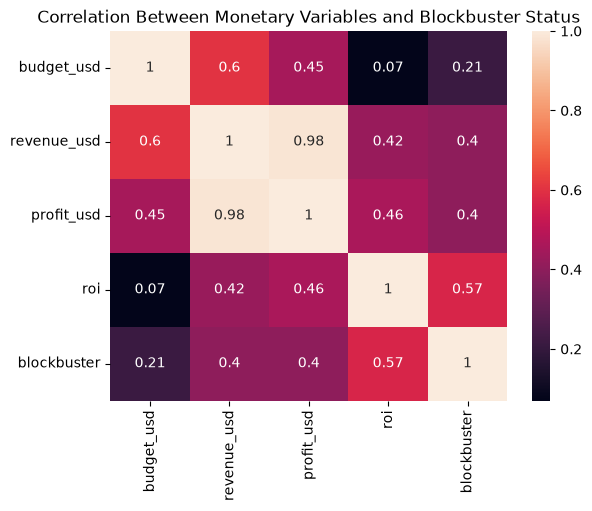

In [71]:
columns=['budget_usd', 'revenue_usd', 'profit_usd', 'roi', 'blockbuster']
plt.title('Correlation Between Monetary Variables and Blockbuster Status')
sns.heatmap(df[columns].corr(), annot=True)
plt.show()

This graph showcases the correlation between multiple numeric variables, specifically ones focusing on finances with the additional blockbuster variable. The strongest correlation is between profit and revenue which we established with the scatter plot (0.98 correlation). However we see that ROI and blockbuster have a moderate correlation. The weakest correlation is between ROI and budget.

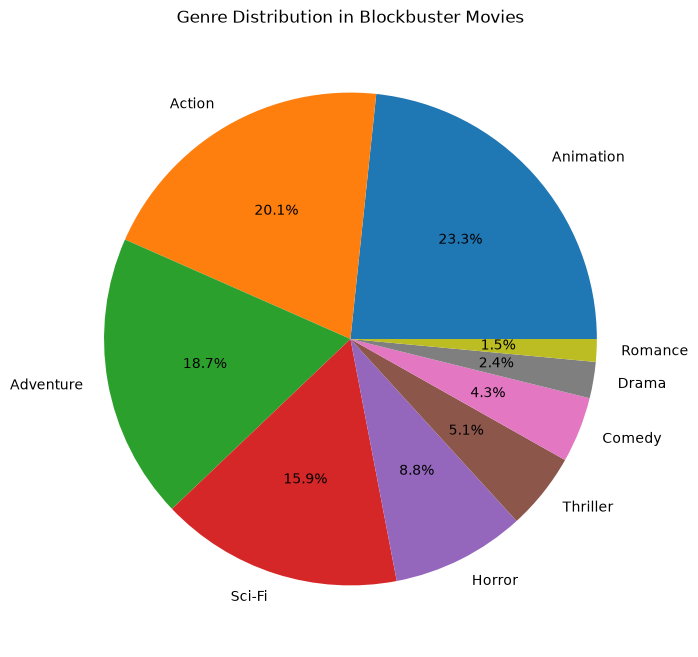

In [10]:
#Pie chart used for presentation
bb=df[df['blockbuster']==1]
genre_count=bb['genre'].value_counts()
plt.figure(figsize=(8,8))
plt.pie(genre_count,labels=genre_count.index, autopct='%1.1f%%')
plt.title('Genre Distribution in Blockbuster Movies')
plt.savefig('piechart_genre_bb.png')
plt.show()

This graph showcases the distribution of genres in the list of blockbuster movies, it shows how the proportions are divided. Animation has the largest proportion with 23.3% while Romance has the least proportion.

## Data Conclusion
Overall, these visualizations helped me explore how genre and financial performance can relate to blockbuster movies. Genres did seem to have a similar movie count yet their profits did differ substantially. For example, adventure has the highest profit and documentary the lowest. Revenue and profit have a strong positive correlation which is partially expected because they directly tie into each other. However, budget and ROI have little to no relationship which suggests that spending more does not equal a better return rate. These findings show patterns but we'd need extra analysis to further pick out what particular movies become blockbusters.